# 05 · Conjuntos pareados y estadística de rangos

**Objetivo:** dar las herramientas de partida para un estudio basado en rangos:

1. generar **pares** con la misma realización de ruido, con señal y sin ella (`X` y `X_noise`);
2. generar conjuntos **independientes** de solo ruido;
3. usar **splits con entornos de ruido disjuntos**;
4. con un estadístico de juguete, calcular rangos, la prueba de Mann–Whitney U, la curva ROC y su AUC, y la prueba de Wilcoxon de rangos con signo para datos pareados.

> ⚠️ **Esto es un ejemplo de uso de las herramientas, no un método recomendado.** Los estadísticos de este notebook (fracción de potencia en una banda y máximo de |X|) están elegidos porque son fáciles de entender, no porque sean buenos detectores. Con 12 señales, además, las cifras son muy ruidosas. El diseño del estudio (qué estadístico, cuántas muestras, qué hipótesis contrastar) es tuyo.

**Requisitos:** tutoriales 01 a 04. Paquete de PSD recomendable (para los splits disjuntos es necesario).

**Tiempo aproximado:** 1–2 minutos (12 señales con su par de ruido y 12 muestras de solo ruido).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'tutorials':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

PSD_PACK = 'psd_pack_o3b.npz'
pack_path = Path(PSD_PACK) if Path(PSD_PACK).is_absolute() else ROOT / PSD_PACK
USE_PACK = pack_path.is_file()
if not USE_PACK:
    warnings.warn(f'No encuentro {pack_path}: uso ruido analítico (curvas de diseño), no las PSD de O3b.')

from gwsim.noise import PsdPackNoise, AnalyticNoise
O3B_GPS = [1256655618.0, 1269363618.0]
noise = PsdPackNoise(pack_path, ['train']) if USE_PACK else AnalyticNoise(O3B_GPS)
C_SIG, C_NOISE = '#d55e00', '#0072b2'

from gwsim.recipe import Physics, RowOptions, simulate_row
from gwsim.config import DEFAULT_CONFIG
from gwsim.priors import sample_parameters, order_masses, add_derived
phys = Physics()
cfg = phys.config

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain

## 1. Splits con entornos de ruido disjuntos

Si eliges o calibras algo (un umbral, un estadístico, una red) con unos datos y lo evalúas con otros, el ruido de la evaluación debe venir de **otros tramos** de O3b. Si no, lo que hayas ajustado puede estar aprovechando particularidades de esos tramos, y la evaluación saldrá optimista. El paquete separa los bloques de ruido en entornos disjuntos con las etiquetas `train`, `val`, `cal` y `test`.

Aquí sacamos las señales de `train` y el ruido independiente de `val`, y comprobamos que no comparten entornos ni bloques.

In [2]:
if USE_PACK:
    noise_val = PsdPackNoise(pack_path, ['val'])
    print('bloques comunes train ∩ val :', set(noise.crop_block) & set(noise_val.crop_block))
    print('entornos comunes train ∩ val:', set(noise.crop_group) & set(noise_val.crop_group))
else:
    noise_val = noise
    print('Con ruido analítico no hay entornos: todas las muestras usan las mismas curvas de diseño.')

bloques comunes train ∩ val : set()
entornos comunes train ∩ val: set()


`set()` significa vacío: no hay solapamiento. En la CLI se consigue lo mismo con `noise.splits` (y una `seed` distinta) en cada configuración; ver `docs/GUIA_PASO_A_PASO.md`, paso 10.

## 2. Pares señal + ruido / solo ruido

Con `outputs = ('X', 'X_noise')`, cada fila devuelve dos entradas con **la misma realización de ruido** n:

- `X` = z-score(procesado(s + n));
- `X_noise` = z-score(procesado(n)).

Eso permite comparar pares: la diferencia entre los dos miembros de un par se debe solo a la señal, porque el ruido se cancela. En la CLI es lo mismo: `"outputs": ["X", "X_noise"]`.

Además generamos un conjunto **independiente** de solo ruido (modo `noise_only`, otras semillas y otro split): esas muestras no comparten ruido con ninguna señal.

In [3]:
N = 12
prior = dict(DEFAULT_CONFIG['prior'])
prior['masses'] = {'distribution': 'components_uniform', 'range': [20.0, 60.0]}
rng = np.random.default_rng(42)
P = add_derived(order_masses(sample_parameters(prior, N, rng)))
target = rng.uniform(8.0, 16.0, N)                 # SNR moderadas, para que la tarea no sea trivial
a_sig = noise.assign(N, rng)
a_ind = noise_val.assign(N, rng)

pairs = RowOptions(physics=phys, mode='snr', outputs=('X', 'X_noise'))
only = RowOptions(physics=phys, mode='noise_only', outputs=('X',))
X_sig, X_pair, X_ind, snr = [], [], [], []
for k in range(N):
    out, meta = simulate_row(P.iloc[k], a_sig['gps'][k], noise.psds(a_sig['block_id'][k], cfg),
                             placement_seed=10_000 + k, gaussian_seed=20_000 + k, target_snr=target[k], opts=pairs)
    X_sig.append(out['X']); X_pair.append(out['X_noise']); snr.append(meta['final_network_snr'])
    out_n, _ = simulate_row(None, a_ind['gps'][k], noise_val.psds(a_ind['block_id'][k], cfg),
                            None, gaussian_seed=30_000 + k, opts=only)
    X_ind.append(out_n['X'])
X_sig, X_pair, X_ind, snr = map(np.asarray, (X_sig, X_pair, X_ind, snr))
print('formas:', X_sig.shape, X_pair.shape, X_ind.shape)
print('SNR de red:', snr.round(1))

formas: (12, 3, 16384) (12, 3, 16384) (12, 3, 16384)
SNR de red: [10.9  8.7  8.9 15.7 15.3 13.6 10.1 15.8 14.2 13.7 11.6 10.2]


## 3. Un estadístico de juguete… y una trampa

Un estadístico **agnóstico al modelo** resume una entrada X en un número T(X) sin usar plantillas de forma de onda. Lo más ingenuo sería la **energía**, Σ X². Pero hay una trampa: `X` está normalizada por detector (media 0, desviación 1), así que Σ X² ≈ 3 × 16384 para *cualquier* entrada, con señal o sin ella. El z-score ha eliminado la información de la energía total.

In [4]:
energy = lambda X: np.sum(X.astype(np.float64) ** 2, axis=(-2, -1))
print('Σ X² con señal  :', energy(X_sig)[:4].round(2))
print('Σ X² solo ruido :', energy(X_ind)[:4].round(2))

Σ X² con señal  : [49152. 49152. 49152. 49152.]
Σ X² solo ruido : [49152. 49152. 49152. 49152.]


Lo que el z-score no borra es **cómo se reparte** esa energía. Usamos dos estadísticos de ejemplo:

- **T_banda**: la fracción de la potencia de la banda de análisis (30–1024 Hz) que cae entre 35 y 300 Hz, sumada sobre los tres detectores. El ruido blanqueado es plano, así que esa fracción es fija en promedio (≈ 0,27 por detector). Una señal CBC de estas masas concentra su potencia ahí y la hace subir.
- **T_max**: el máximo de |X| sobre los tres detectores y los 4 s. Una señal concentrada en el tiempo puede producir un valor extremo.

Repetimos el aviso: son estadísticos de juguete.

In [5]:
freqs = np.fft.rfftfreq(cfg.length, d=cfg.delta_t)
analysis = (freqs >= 30.0) & (freqs < 1024.0)
sub = (freqs >= 35.0) & (freqs < 300.0)

def T_band(X):
    p = np.abs(np.fft.rfft(X.astype(np.float64), axis=-1)) ** 2
    return (p[..., sub].sum(-1) / p[..., analysis].sum(-1)).sum(-1)

def T_max(X):
    return np.abs(X).max(axis=(-2, -1))

stats_tab = {name: (f(X_sig), f(X_pair), f(X_ind)) for name, f in (('T_banda', T_band), ('T_max', T_max))}
for name, (s, p, i) in stats_tab.items():
    print(f'{name}: señal {s.mean():.4f}  par solo ruido {p.mean():.4f}  ruido independiente {i.mean():.4f}')

T_banda: señal 0.8005  par solo ruido 0.7866  ruido independiente 0.7940
T_max: señal 4.4578  par solo ruido 4.4101  ruido independiente 4.4015


## 4. Rangos y la prueba de Mann–Whitney U (muestras independientes)

Un enfoque **basado en rangos** no usa los valores de T, solo su **orden**:

1. se juntan las n₁ muestras con señal y las n₂ de ruido independiente;
2. se ordenan y a cada una se le asigna su rango: 1 la menor y n₁ + n₂ la mayor; los empates reciben la media de sus rangos.

Así el resultado no depende de la escala ni de la forma de la distribución de T.

Si R₁ es la suma de los rangos de las señales, el estadístico de Mann–Whitney es

U = R₁ − n₁(n₁ + 1)/2,

y cuenta cuántos pares (señal, ruido) tienen T(señal) > T(ruido); un empate cuenta ½. Bajo la hipótesis nula (señal y ruido tienen la misma distribución de T), U está centrado en n₁n₂/2. La prueba unilateral (`alternative='greater'`) pregunta si T tiende a ser mayor con señal.

In [6]:
from scipy.stats import rankdata, mannwhitneyu, wilcoxon
for name, (s, _, i) in stats_tab.items():
    ranks = rankdata(np.concatenate([s, i]))
    n1, n2 = len(s), len(i)
    U = ranks[:n1].sum() - n1 * (n1 + 1) / 2
    res = mannwhitneyu(s, i, alternative='greater')
    print(f'{name}: U a mano = {U:.1f}, U de scipy = {res.statistic:.1f}, p = {res.pvalue:.2e}, '
          f'AUC = U/(n1·n2) = {U / (n1 * n2):.3f}')

T_banda: U a mano = 84.0, U de scipy = 84.0, p = 2.53e-01, AUC = U/(n1·n2) = 0.583
T_max: U a mano = 64.0, U de scipy = 64.0, p = 6.88e-01, AUC = U/(n1·n2) = 0.444


## 5. Curva ROC y AUC

Si usamos T como detector ("hay señal si T ≥ umbral"), cada umbral da:

- una **tasa de verdaderos positivos** (TPR): la fracción de señales por encima del umbral;
- una **tasa de falsos positivos** (FPR): la fracción de ruido por encima del umbral.

La curva ROC es la de TPR frente a FPR al barrer el umbral. Su área (**AUC**) es la probabilidad de que una señal elegida al azar tenga mayor T que un ruido elegido al azar. Es exactamente U/(n₁n₂): **la ROC es la versión gráfica de la prueba de rangos**. AUC = 0,5 significa que T no distingue nada; AUC = 1, que separa perfectamente.

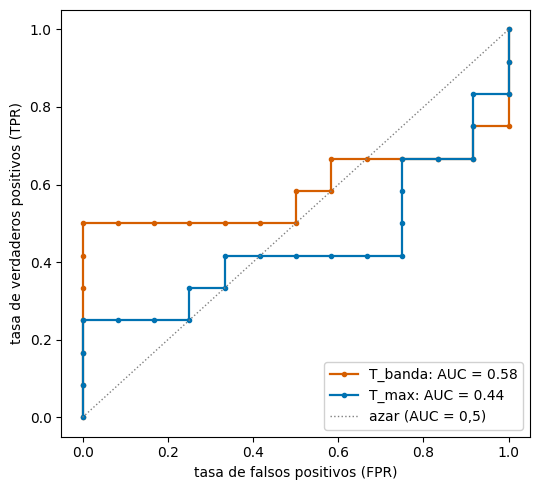

In [7]:
def roc(sig, noi):
    thresholds = np.unique(np.concatenate([sig, noi]))[::-1]
    tpr = np.array([0.0] + [np.mean(sig >= u) for u in thresholds])
    fpr = np.array([0.0] + [np.mean(noi >= u) for u in thresholds])
    return fpr, tpr

fig, ax = plt.subplots(figsize=(5.5, 5))
for (name, (s, _, i)), c in zip(stats_tab.items(), (C_SIG, C_NOISE)):
    fpr, tpr = roc(s, i)
    ax.plot(fpr, tpr, color=c, lw=1.6, marker='.', label=f'{name}: AUC = {np.trapezoid(tpr, fpr):.2f}')
ax.plot([0, 1], [0, 1], color='0.5', ls=':', lw=1, label='azar (AUC = 0,5)')
ax.set_xlabel('tasa de falsos positivos (FPR)')
ax.set_ylabel('tasa de verdaderos positivos (TPR)')
ax.legend(loc='lower right', framealpha=0.9)
plt.tight_layout(); plt.show()

Con 12 + 12 muestras, la curva va a saltos de 1/12 y el AUC tiene una incertidumbre grande, del orden de ±0,1. Para conclusiones reales necesitas muchas más muestras (tutorial 06) y una estimación de la incertidumbre, por ejemplo bootstrap.

## 6. Pares: la prueba de Wilcoxon de rangos con signo

Las secciones 4 y 5 comparan **muestras independientes**: señales frente a otro ruido. Con los **pares** (`X`, `X_noise`) se puede hacer otra pregunta, *¿cuánto cambia T al añadir la señal a este mismo ruido?*, y para eso la prueba es otra:

- se calculan las diferencias dᵢ = T(Xᵢ) − T(X_noise,ᵢ), una por par;
- se ordenan los |dᵢ| y se suman los rangos de las diferencias positivas (W⁺);
- bajo la nula (sumar la señal no cambia T), cada dᵢ es igual de probable con signo + o −, y W⁺ está centrado en n(n + 1)/4.

**Por qué importa:** en cada diferencia, la variabilidad del ruido (la que hace que T fluctúe de una muestra a otra) se cancela casi por completo. Por eso la prueba pareada suele detectar efectos mucho más pequeños con las mismas muestras. Ojo: ese poder extra no lo tendrías con datos reales, en los que nunca tienes el mismo ruido con señal y sin ella. Los pares sirven para **entender** el estadístico, no para estimar cómo funcionaría en un experimento.

T_banda: Wilcoxon pareado W+ = 78, p = 2.44e-04   |   Mann–Whitney ignorando los pares p = 1.07e-01
T_max: Wilcoxon pareado W+ = 35, p = 6.33e-01   |   Mann–Whitney ignorando los pares p = 3.98e-01


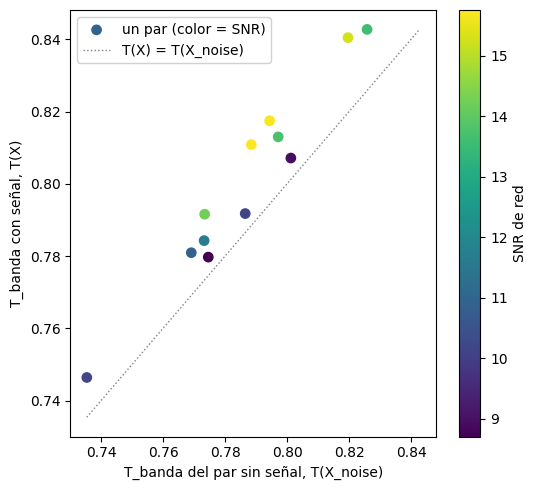

In [8]:
for name, (s, p, _) in stats_tab.items():
    w = wilcoxon(s - p, alternative='greater')
    mw = mannwhitneyu(s, p, alternative='greater')   # mal planteado a propósito: ignora el emparejamiento
    print(f'{name}: Wilcoxon pareado W+ = {w.statistic:.0f}, p = {w.pvalue:.2e}   |   '
          f'Mann–Whitney ignorando los pares p = {mw.pvalue:.2e}')

s, p, _ = stats_tab['T_banda']
fig, ax = plt.subplots(figsize=(5.5, 5))
sc = ax.scatter(p, s, c=snr, cmap='viridis', s=45, label='un par (color = SNR)')
lo, hi = min(p.min(), s.min()), max(p.max(), s.max())
ax.plot([lo, hi], [lo, hi], color='0.5', ls=':', lw=1, label='T(X) = T(X_noise)')
ax.set_xlabel('T_banda del par sin señal, T(X_noise)')
ax.set_ylabel('T_banda con señal, T(X)')
fig.colorbar(sc, ax=ax, label='SNR de red')
ax.legend(loc='upper left', framealpha=0.9)
plt.tight_layout(); plt.show()

Los puntos por encima de la diagonal son pares en los que añadir la señal subió T. Se separan más de la diagonal cuanto mayor es la SNR.

## Resumen de las herramientas

| Pregunta | Datos | Prueba |
|---|---|---|
| ¿T distingue señal de ruido? | señales frente a ruido **independiente** (otro split, otras semillas) | Mann–Whitney U, ROC y AUC |
| ¿Cómo responde T a la señal, manteniendo el ruido? | pares `X` / `X_noise` | Wilcoxon de rangos con signo |
| ¿Generaliza lo ajustado? | ajustar en `train`, evaluar en `val`/`test` | lo anterior, en el split de evaluación |

Recuerda que todo esto es con ruido **gaussiano** (`docs/VALIDEZ.md`).

**Siguiente:** `06_generacion_masiva.ipynb`.